In [2]:
import numpy as np
def simulate_lmm(forward_rates_0, vols, corr_matrix, tau, T_max, n_steps, n_paths):
    """
    Simulation Monte Carlo du LIBOR Market Model (LMM).
    
    Parameters:
    - forward_rates_0: Vecteur des taux forward initiaux [L_1(0), L_2(0), ..., L_N(0)]
    - vols: Volatilité de chaque taux forward [sigma_1, ..., sigma_N]
    - corr_matrix: Matrice de corrélation NxN entre les taux forward
    - tau: Ténor des taux (ex: 0.5 pour des taux 6 mois)
    """
    n_rates = len(forward_rates_0)
    dt = T_max / n_steps
    
    # Tensor des taux : [Pas de temps, Taux_k, Trajectoire_i]
    L = np.zeros((n_steps + 1, n_rates, n_paths))
    for k in range(n_rates):
        L[0, k, :] = forward_rates_0[k]

    # Décomposition de Cholesky pour générer des mouvements browniens corrélés
    L_chol = np.linalg.cholesky(corr_matrix)

    for step in range(n_steps):
        # Tirages normaux indépendants puis corrélés
        Z_uncorr = np.random.normal(0, 1, size=(n_rates, n_paths))
        Z_corr = L_chol @ Z_uncorr

        for k in range(n_rates):
            # Calcul du drift de non-arbitrage sous la mesure spot LIBOR
            drift_k = np.zeros(n_paths)
            for j in range(k + 1):
                numerator = tau * L[step, j, :] * vols[j] * vols[k] * corr_matrix[j, k]
                denominator = 1 + tau * L[step, j, :]
                drift_k += numerator / denominator

            # Évolution log-normale exacte du taux forward L_k
            sigma_k = vols[k]
            diffusion = sigma_k * np.sqrt(dt) * Z_corr[k, :]
            drift_term = (drift_k - 0.5 * sigma_k**2) * dt
            
            L[step + 1, k, :] = L[step, k, :] * np.exp(drift_term + diffusion)

    return L

# Exemple d'utilisation (3 taux forward simulés simultanément)
fwd_0 = [0.025, 0.028, 0.031]  # Taux forward à 6M, 12M, 18M
vols = [0.15, 0.18, 0.20]       # Volatilités log-normales
rho = np.array([               # Matrice de corrélation entre les échéances
    [1.00, 0.85, 0.70],
    [0.85, 1.00, 0.88],
    [0.70, 0.88, 1.00]
])

lmm_paths = simulate_lmm(fwd_0, vols, rho, tau=0.5, T_max=2, n_steps=100, n_paths=1000)
print("Forme du tenseur LMM (Pas de temps, Nombre de taux, Trajectoires):", lmm_paths.shape)

Forme du tenseur LMM (Pas de temps, Nombre de taux, Trajectoires): (101, 3, 1000)


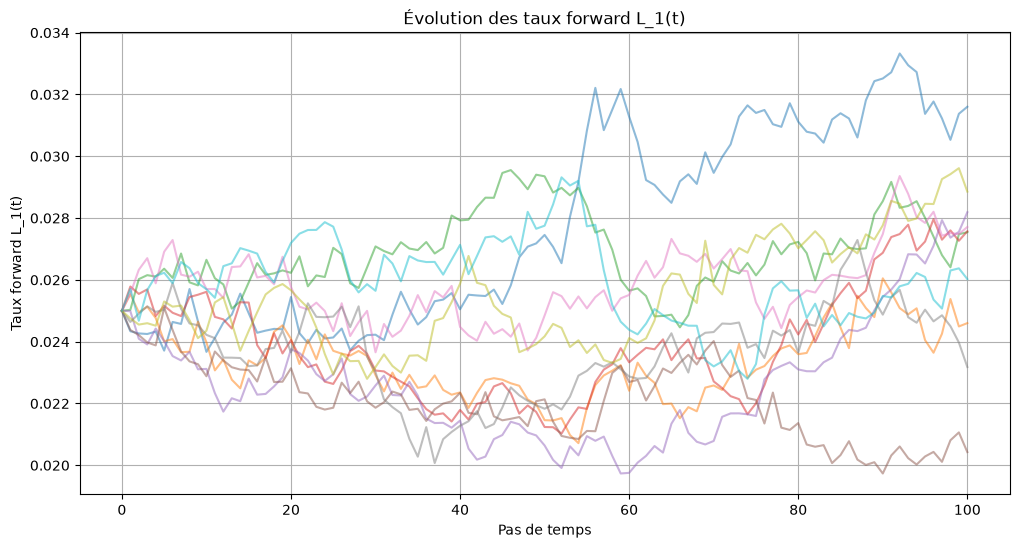

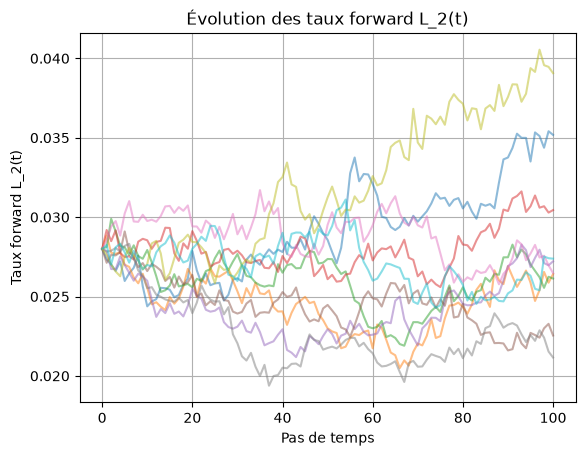

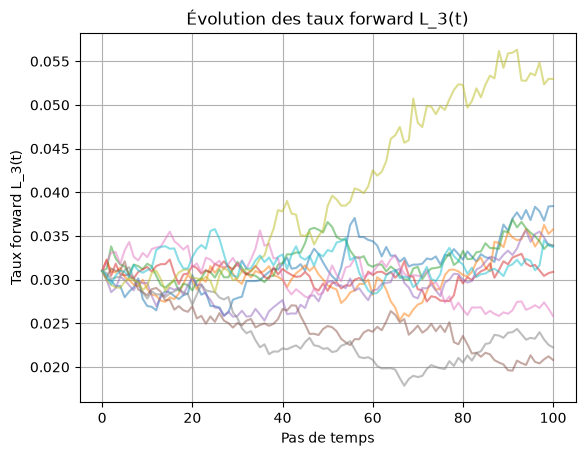

In [3]:
# simulation de l'évolution des taux forward sur 2 ans avec 100 pas de temps et 1000 trajectoires.
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
for k in range(len(fwd_0)):
    plt.plot(lmm_paths[:, k, :10], alpha=0.5)  # Affiche les 10 premières trajectoires pour chaque taux
    plt.title(f'Évolution des taux forward L_{k+1}(t)')
    plt.xlabel('Pas de temps')
    plt.ylabel(f'Taux forward L_{k+1}(t)')
    plt.grid()
    plt.show()

